# Tumor subpopulations: resolution and seed

The tumor subpopulations are defined once and then frozen for the matching
analysis. This notebook sweeps Leiden resolution on the joint latent space,
compares tumor-only and full-graph clustering, checks seed stability, and saves
the shared artifact read by the downstream notebooks.

Resolution 0.9 on the tumor-only graph is the matching frame. Full-graph
resolution 1.0 is a supporting view. The notebook does not fit a model as it uses
the saved config-10 joint scANVI latent and the processed AnnData objects.


The sequence is:

1. build the full-gene combined object from the processed data and the saved
   joint latent
2. sweep tumor-only and full-graph Leiden resolution at graph seed 0
3. audit the chosen tumor-only clustering and check Leiden-seed stability
4. select the working seed with the fragment/over-merge screen
5. save the artifact with the frozen labels and settings

In [1]:
from pathlib import Path
import sys

import anndata as ad
import pandas as pd
import scanpy as sc

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import model_io
from src.bio import clustering, plots
from src.utils import load_config

In [2]:
APPROACH = "joint"
CONFIG_ID = 10
NUM_HVG = 3000

GRAPH_SEED = 0
SWEEP_SEED = 0
LEIDEN_SEEDS = [0, 1, 2, 3, 4]

RESOLUTION_SWEEP = [0.5, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.5, 2.0]

TUMOR_RES = 0.9
FULL_RES = 1.0

MIN_LINE_SUBGROUP_CELLS = 50

## Inputs

In [3]:
cfg = load_config()
paths = cfg["paths"]
run_dir = (
    ROOT
    / paths["hpo"]["runs"]
    / f"hvg{NUM_HVG}"
    / f"config_{CONFIG_ID:02d}"
    / APPROACH
)
if not (run_dir / "DONE").exists():
    raise FileNotFoundError(
        f"No completed run at {run_dir}; check APPROACH/CONFIG_ID/NUM_HVG."
    )

adata_tumor = ad.read_h5ad(ROOT / paths["processed"]["pp_tumor"])
adata_cl = ad.read_h5ad(ROOT / paths["processed"]["pp_cell_line"])
run = model_io.load_run_latent(run_dir, adata_tumor, adata_cl, APPROACH)

print(f"tumor {adata_tumor.shape}, cell line {adata_cl.shape}")
print(f"Run: {run_dir.relative_to(ROOT)}")

tumor (108131, 28617), cell line (2162, 28617)
Run: models/hpo/runs/hvg3000/config_10/joint


In [4]:
hvg_genes = (run_dir.parents[1] / "hvg_genes.txt").read_text().splitlines()
combined_full = clustering.build_combined_full_adata(
    adata_tumor,
    adata_cl,
    run["latent"],
    run["obs_names"],
    hvg_genes,
    tumor_metadata_path=ROOT / paths["raw_data"]["tumor_metadata"],
)
del adata_tumor, adata_cl

print(f"full combined adata {combined_full.shape}")
print(
    f"HVG list: {len(hvg_genes)} entries, {len(set(hvg_genes))} unique; "
    f"var flag {int(combined_full.var['hvg'].sum())}"
)
print(f"obs columns: {list(combined_full.obs.columns)}")

tumor_adata = combined_full[combined_full.obs["dataset"].eq("tumor")].copy()
print(f"tumor subset {tumor_adata.shape}")

full combined adata (110293, 28617)
HVG list: 3000 entries, 3000 unique; var flag 3000
obs columns: ['cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'biosample_id', 'mlh1_status', 'sex', 'tissue_site', 'pathological_stage', 'tumor_grade', 'TissueSource', 'ProcessingMethod', 'TumorStage', 'LymphNodeStatus', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo']
tumor subset (108131, 28617)


In [ ]:
# Combined graph: used by UMAP and the full-graph Leiden sweep.
sc.pp.neighbors(combined_full, use_rep="X_latent", random_state=GRAPH_SEED)
sc.tl.umap(combined_full, random_state=GRAPH_SEED)

print(f"combined graph: {list(combined_full.obsp)}")
print(f"X_umap: {combined_full.obsm['X_umap'].shape}")

## Tumor-only Leiden sweep

Tumor-only clustering keeps the Pelka reference frame intact: cell line cells never influence the tumor subpopulations. The graph below is computed on `tumor_adata` only, not on the combined object. One graph at graph seed 0, one Leiden run per resolution at Leiden seed 0, labels copied back onto the combined object for plotting.

In [ ]:
# Tumor-only graph: separate from the combined graph so cell lines cannot influence the tumor clusters.
sc.pp.neighbors(tumor_adata, use_rep="X_latent", random_state=GRAPH_SEED)
print(f"tumor graph: {list(tumor_adata.obsp)}")

In [6]:
tumor_resolution_summary = clustering.run_tumor_leiden_sweep(
    combined_full, tumor_adata, RESOLUTION_SWEEP, sweep_seed=SWEEP_SEED
)
tumor_resolution_summary

,resolution,n_clusters,min_size,max_size
0,0.5,11,54,30895
1,0.7,14,54,25457
2,0.8,14,54,21875
3,0.9,16,1458,18464
4,1.0,19,52,13725
5,1.1,22,129,15987
6,1.2,23,652,13417
7,1.3,26,209,11790
8,1.5,27,53,8354
9,2.0,36,106,7286


### UMAP view

In [7]:
combined_full

AnnData object with n_obs × n_vars = 110293 × 28617
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'biosample_id', 'mlh1_status', 'sex', 'tissue_site', 'pathological_stage', 'tumor_grade', 'TissueSource', 'ProcessingMethod', 'TumorStage', 'LymphNodeStatus', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'tumor_leiden_res0.5', 'tumor_leiden_res0.7', 'tumor_leiden_res0.8', 'tumor_leiden_res0.9', 'tumor_leiden_res1.0', 'tumor_leiden_res1.1', 'tumor_leiden_res1.2', 'tumor_leiden_res1.3', 'tumor_leiden_res1.5', 'tumor_leiden_res2.0'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'hvg'
    uns: 'log1p', 'neighbors', 'umap'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

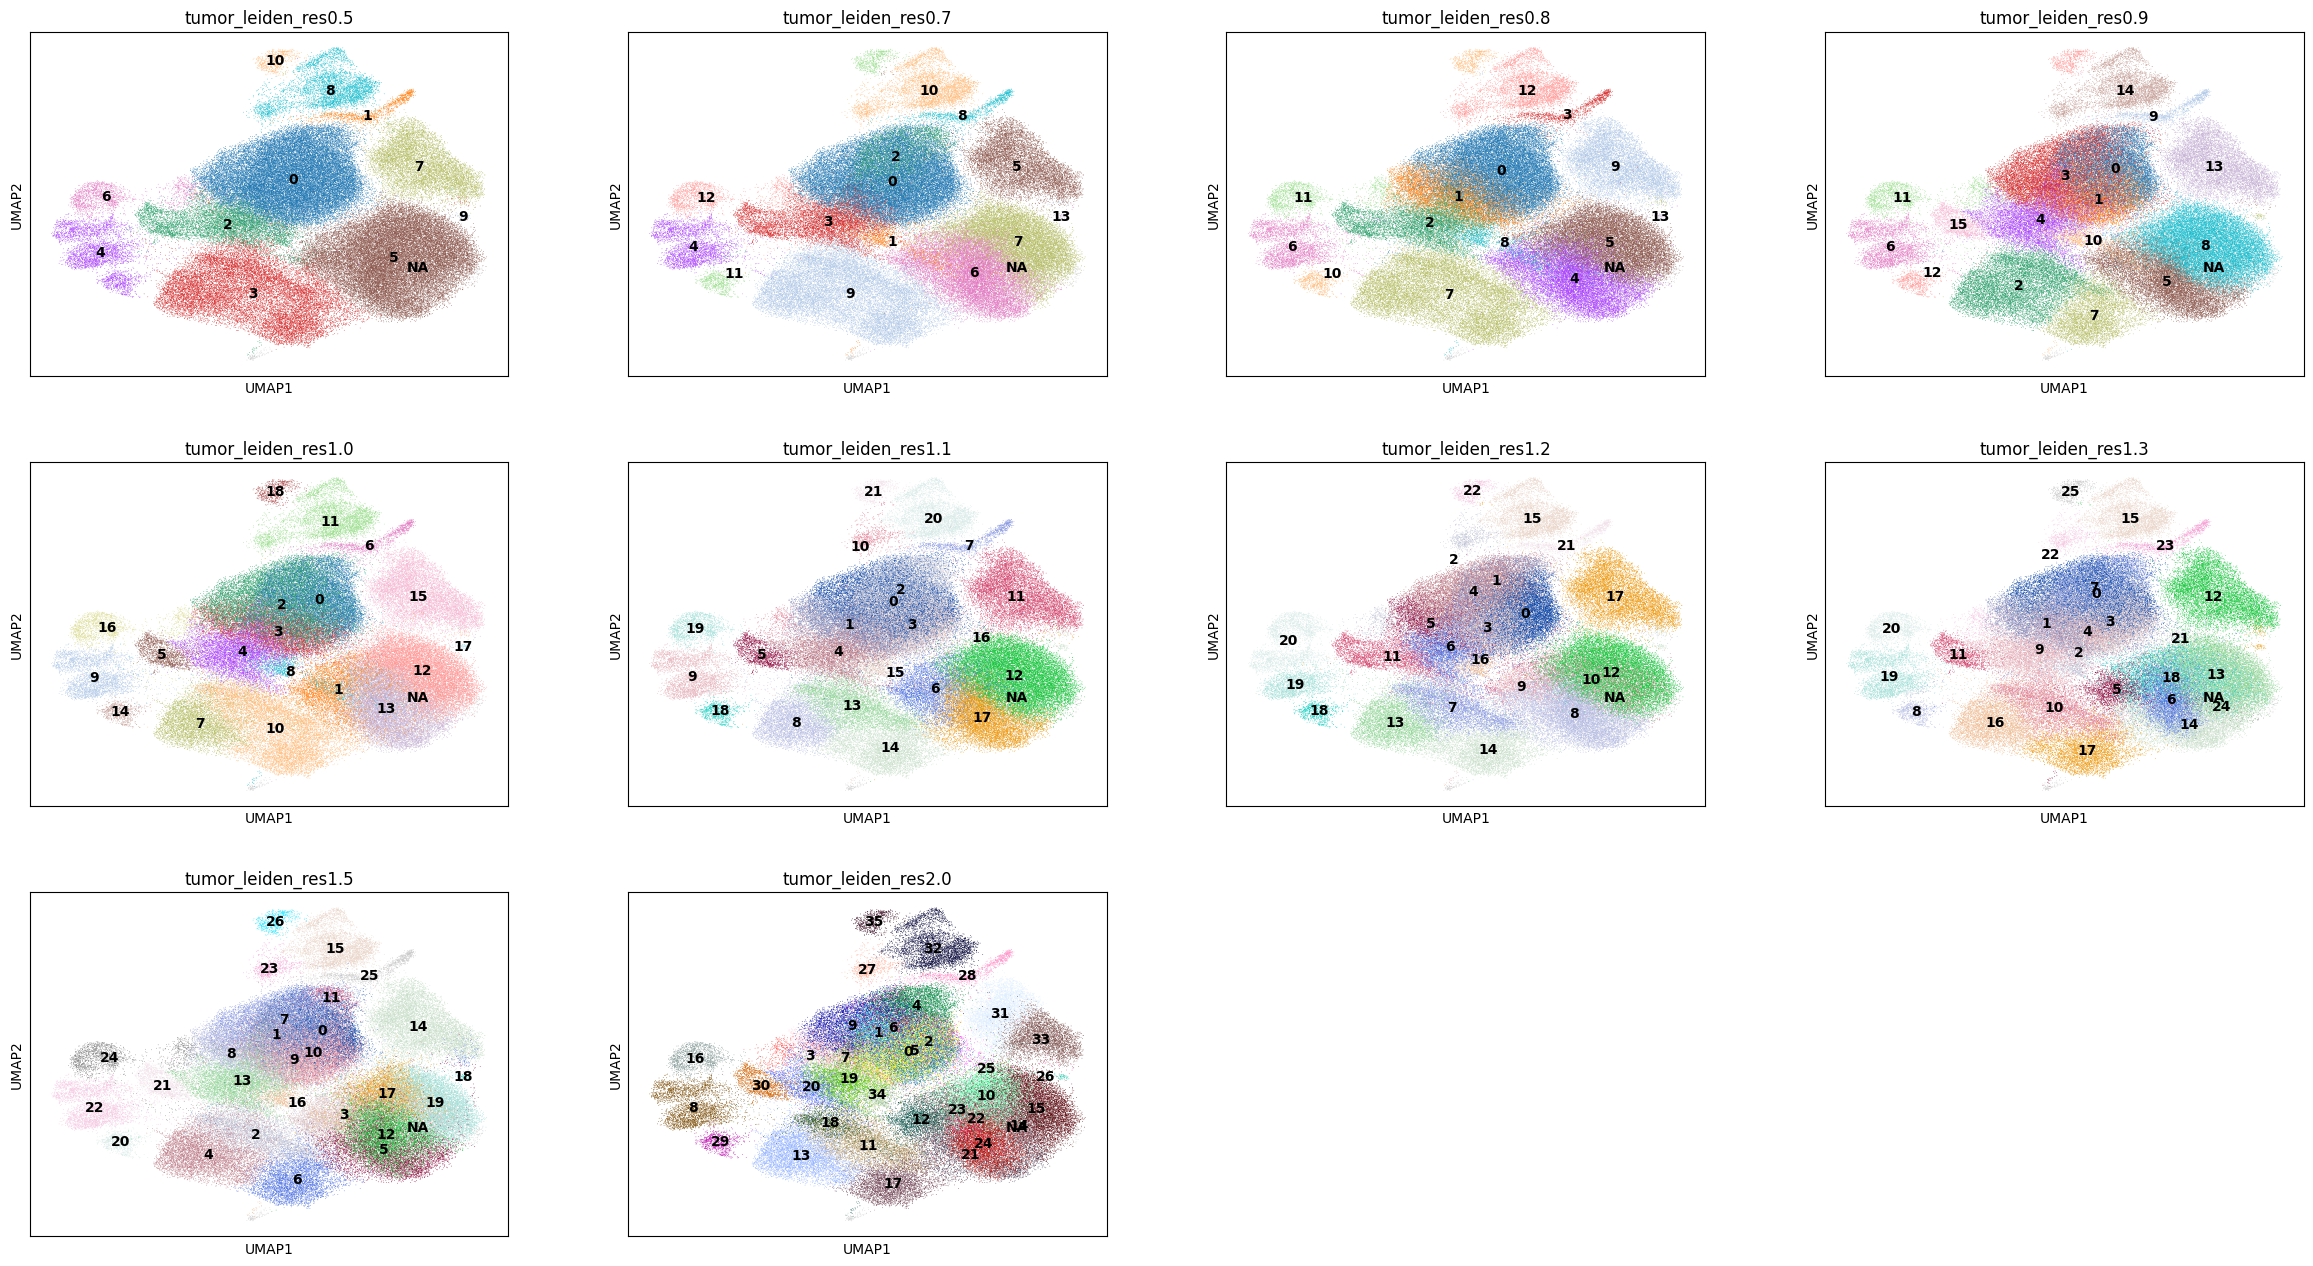

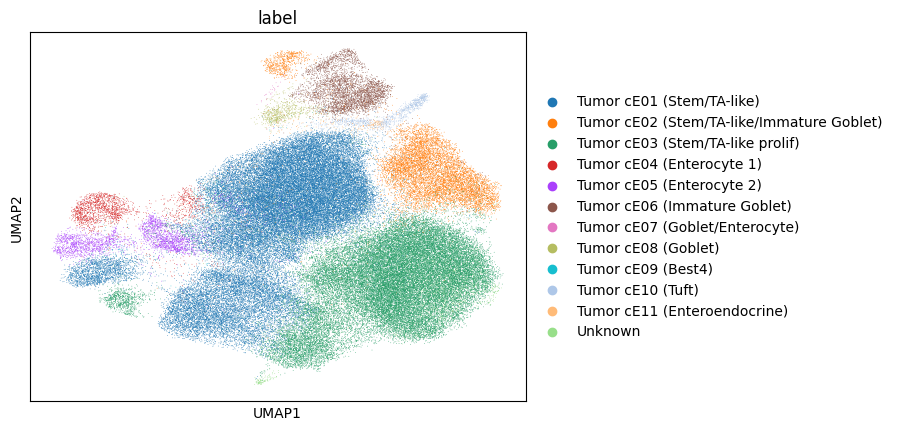

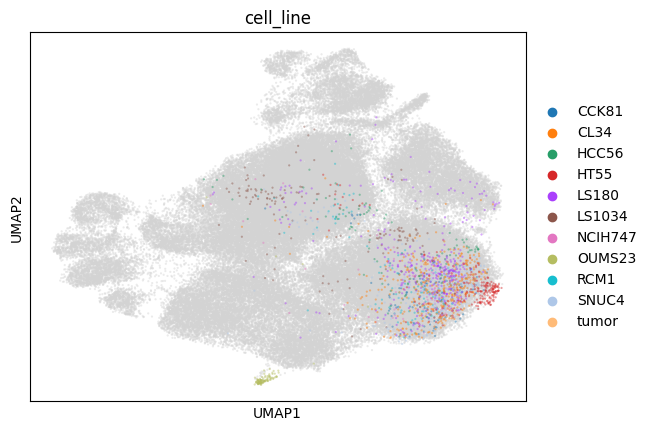

In [8]:
plots.plot_leiden_sweep(combined_full, "tumor", RESOLUTION_SWEEP)

## Full-graph Leiden sweep
The full clustering runs on all 110,293 cells (cell lines + tumor). It is the supporting view: it defines joint cell line/tumor neighborhoods and is the basis of the (possibly) future cell line subgroup definition, but it is not the match target.

In [9]:
full_resolution_summary = clustering.run_full_leiden_sweep(
    combined_full, RESOLUTION_SWEEP, sweep_seed=SWEEP_SEED
)
full_resolution_summary

,resolution,n_clusters,min_size,max_size
0,0.5,11,54,29890
1,0.7,16,55,18458
2,0.8,15,74,17144
3,0.9,19,56,18140
4,1.0,19,657,13065
5,1.1,20,661,12634
6,1.2,22,228,10678
7,1.3,26,246,9690
8,1.5,26,325,8828
9,2.0,35,57,8216


### UMAP view

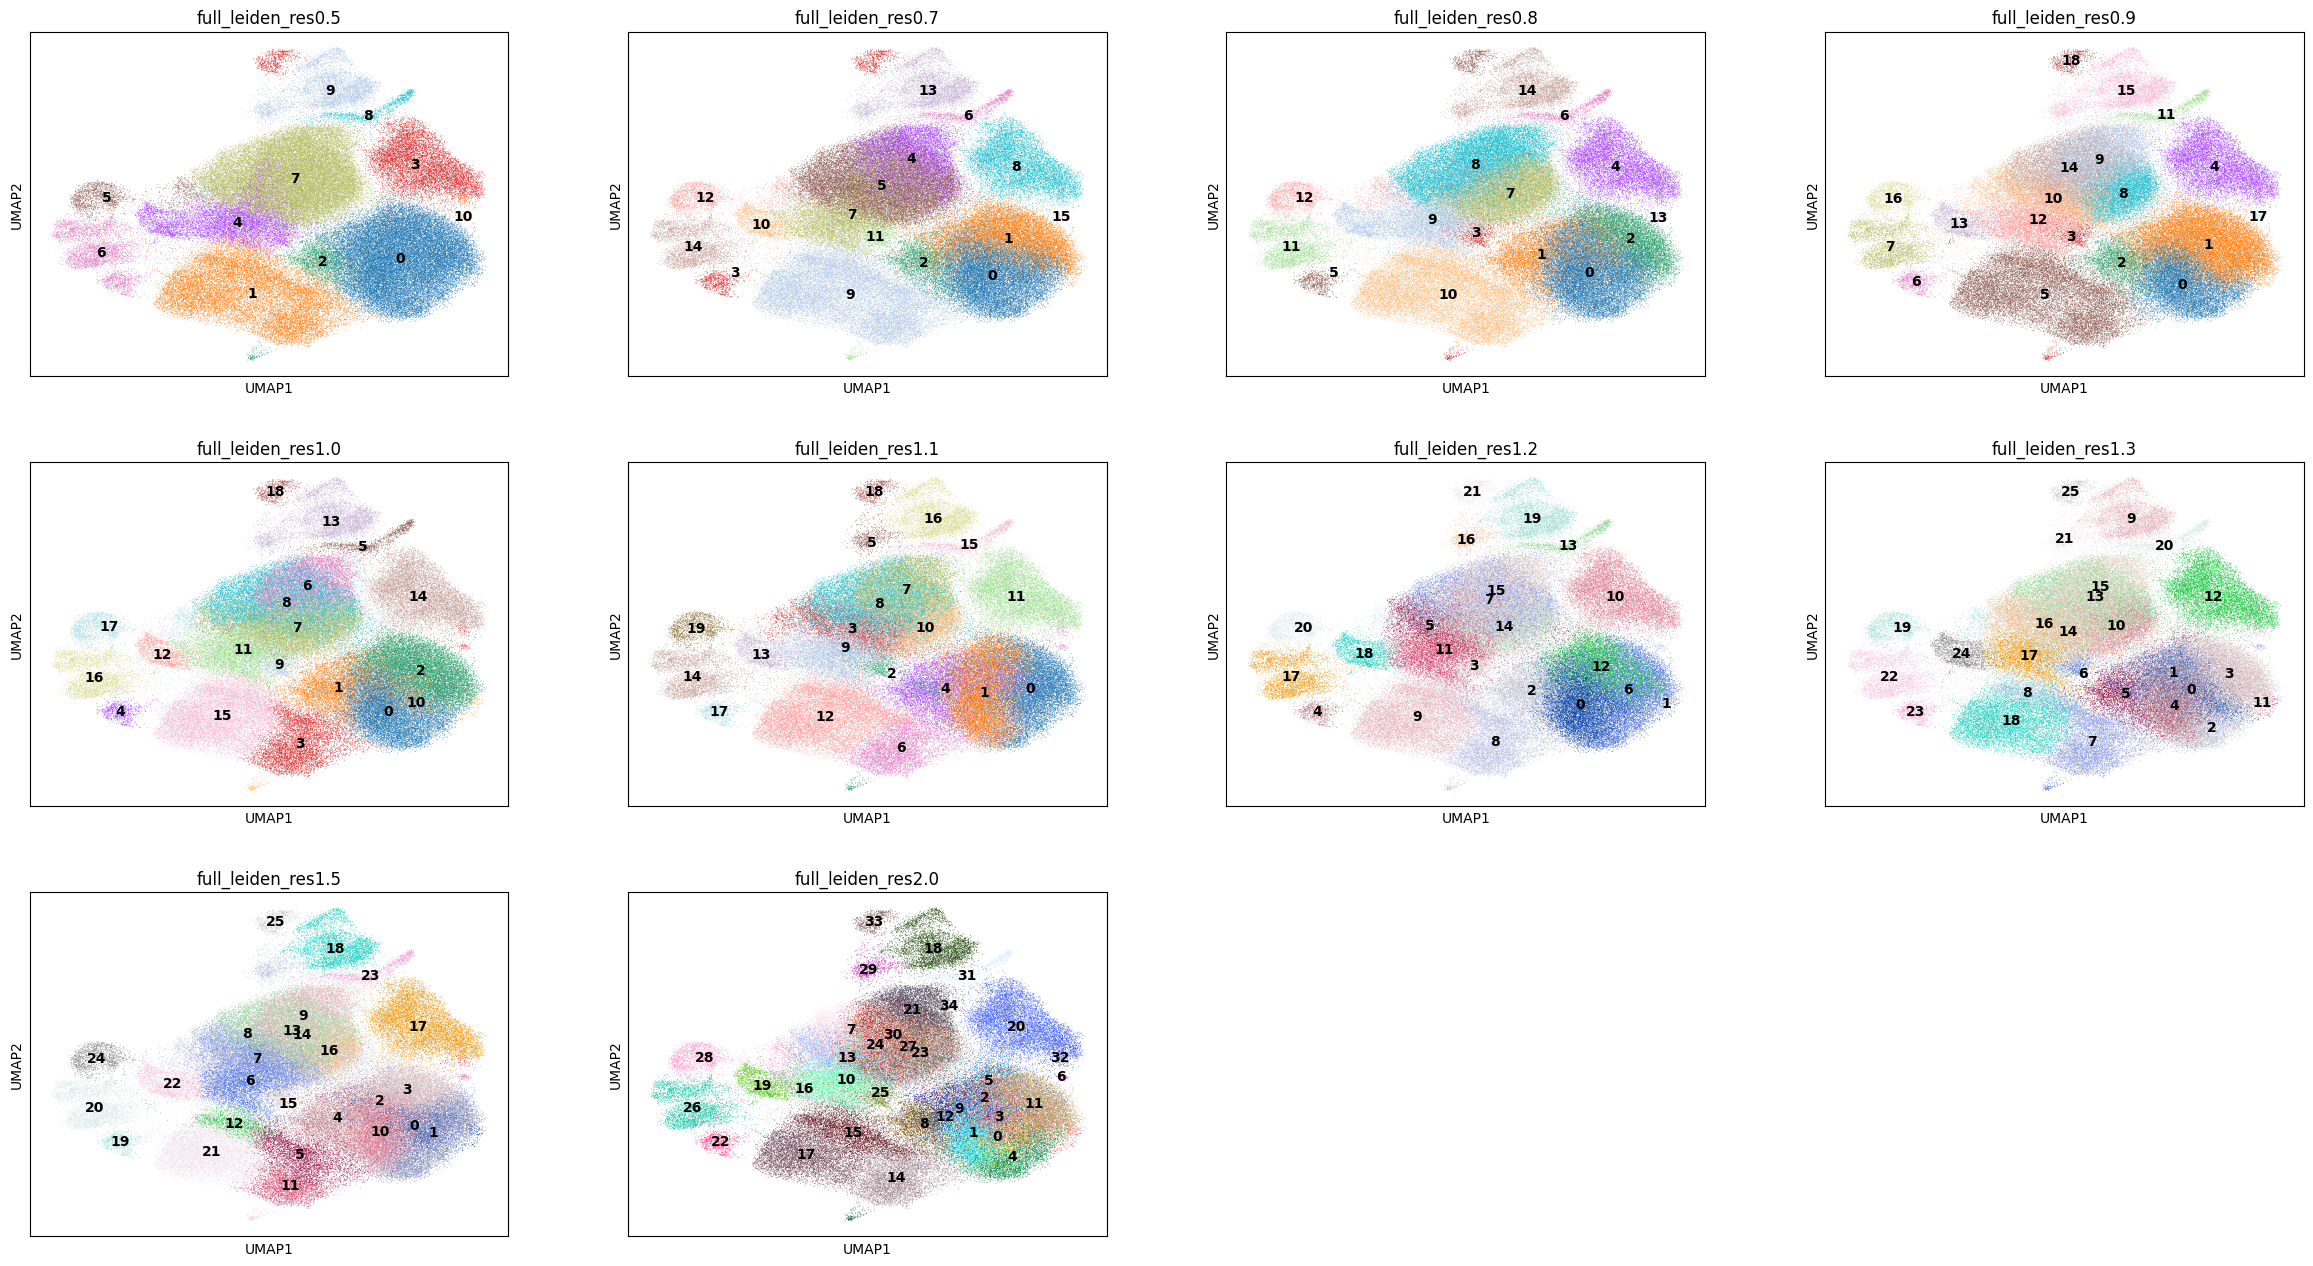

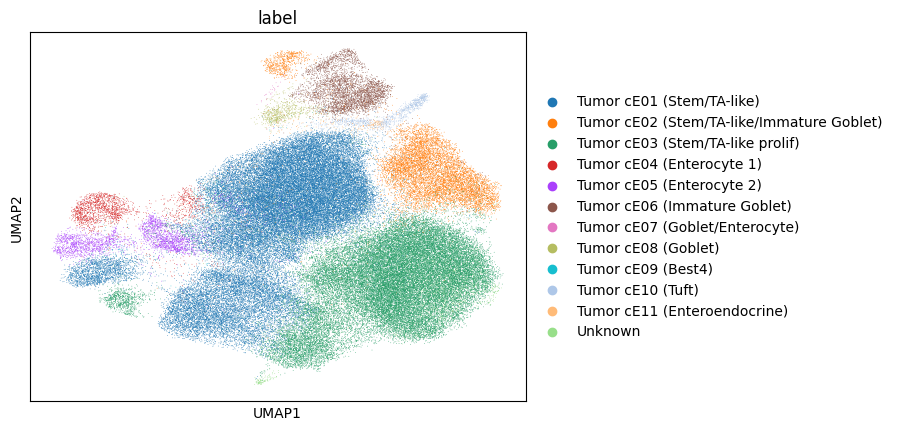

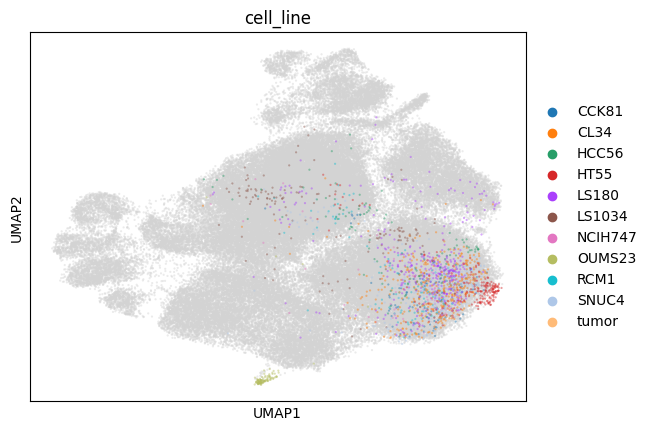

In [10]:
plots.plot_leiden_sweep(combined_full, "full", RESOLUTION_SWEEP)

## Resolution decision

Tumor-only clustering is the matching frame: cell line cells must not influence the tumor subpopulations used as the kNN reference. The full-graph clustering is a supporting view of the joint structure and is not used for matching. Both sweeps are shown above so the two views can be compared.

In [11]:
leiden_scores = clustering.score_leiden_sweep(combined_full)
leiden_scores

,leiden_key,n_clusters,min_cluster_size,median_cluster_size,max_cluster_size,small_clusters_lt_50,adjusted_mutual_info,balanced_label_concentration,line_subgroups_le_50,line_subgroups_gt_50
0,tumor_leiden_res0.5,11,54,4873.0,30895,0,0.618095,0.715167,0,0
1,tumor_leiden_res0.7,14,54,4509.5,25457,0,0.557507,0.676018,0,0
2,tumor_leiden_res0.8,14,54,6574.0,21875,0,0.547507,0.664394,0,0
3,tumor_leiden_res0.9,16,1458,5304.0,18464,0,0.560776,0.658289,0,0
4,tumor_leiden_res1.0,19,52,5424.0,13725,0,0.525492,0.638016,0,0
5,tumor_leiden_res1.1,22,129,5092.0,15987,0,0.519553,0.609422,0,0
6,tumor_leiden_res1.2,23,652,4146.0,13417,0,0.503712,0.606068,0,0
7,tumor_leiden_res1.3,26,209,4501.5,11790,0,0.503742,0.604514,0,0
8,tumor_leiden_res1.5,27,53,3986.0,8354,0,0.496942,0.604158,0,0
9,tumor_leiden_res2.0,36,106,3035.0,7286,0,0.468492,0.543886,0,0


The table supports the two frozen candidates:

- **Tumor-only resolution 0.9** has no clusters below 50 cells at seed 0, a clear AMI gain over lower resolutions, and cluster sizes that stay interpretable. Higher resolutions start to fragment small populations.
- **Full resolution 1.0** has no clusters below 50 cells at seed 0 and a high AMI at a balanced cluster-size profile; resolutions above 1.0 mainly add small fragments.

The next cells audit the tumor-only clustering and check both candidates for Leiden-seed stability.

## Cluster audit

Per-subpopulation sanity check for the chosen tumor-only frame: cluster size,
dominant Pelka state, and label diversity. The cell-line columns of the audit
are trivial here because every cell in the tumor-only frame is tumor.

In [ ]:
t_key = f"tumor_leiden_res{TUMOR_RES}"
f_key = f"full_leiden_res{FULL_RES}"

tumor_audit = clustering.cluster_audit(combined_full, t_key)
tumor_audit

### Cell-line subgroups in the full clustering

Counts of each cell line per full-graph cluster. `usable` flags cell line ×
cluster pairs with at least 50 cells. This is the exploratory view for a
possible line-subgroup matching design; the current matching uses whole cell
lines.

In [14]:
line_subgroups = clustering.line_subgroups_table(
    combined_full, f_key, min_cells=MIN_LINE_SUBGROUP_CELLS
)
line_subgroups

,line,full_cluster,n_cells,usable
0,SNUC4,2,231,True
1,CL34,0,205,True
2,SNUC4,0,196,True
3,LS180,2,195,True
4,CL34,2,184,True
...,...,...,...,...
77,OUMS23,3,1,False
78,NCIH747,5,1,False
79,NCIH747,1,1,False
80,NCIH747,15,1,False


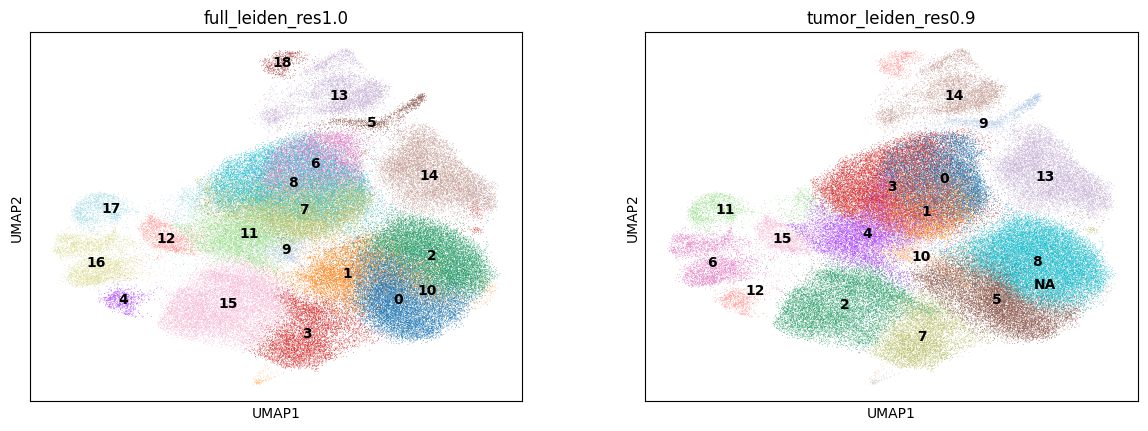

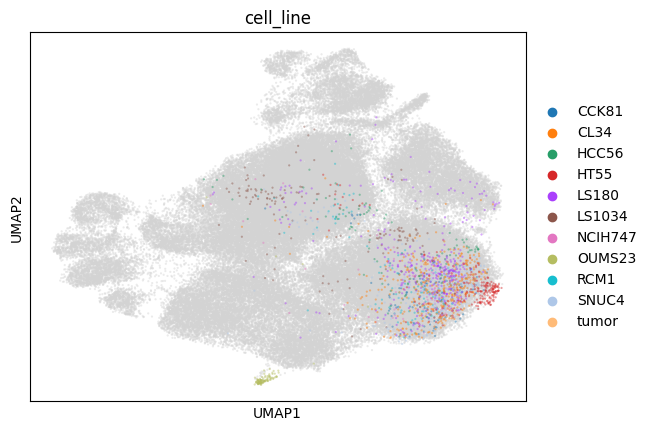

In [ ]:
sc.pl.umap(combined_full, color=[f_key, t_key], legend_loc="on data")
sc.pl.umap(combined_full, color="label")

## Seed stability

The neighbor graph is fixed at graph seed 0; only the Leiden random state
changes. The working seed is selected by screening the tumor-only partitions for
fragments (<50 cells) and over-merging (>15% of cells in one cluster), then
taking the least over-merged valid partition. Pelka AMI, label mixing, and the
pairwise ARI are reported as diagnostics, not as the selector.


In [16]:
tumor_partitions = clustering.leiden_seed_partitions(
    tumor_adata, TUMOR_RES, LEIDEN_SEEDS
)
tumor_seed_summary, tumor_seed_pairwise, tumor_mean_ari = (
    clustering.seed_stability_tables(tumor_partitions)
)
tumor_seed_summary

,seed,n_clusters,min_cluster_size,median_cluster_size,max_cluster_size
0,0,16,1458,5304.0,18464
1,1,16,55,6303.0,17767
2,2,18,52,5537.5,13125
3,3,18,652,5975.0,12126
4,4,17,659,7001.0,12683


In [17]:
tumor_seed_pairwise

,seed_a,seed_b,ARI,AMI
0,0,1,0.529927,0.722708
1,0,2,0.538693,0.739665
2,0,3,0.587362,0.753771
3,0,4,0.498560,0.717510
4,1,2,0.636280,0.774082
5,1,3,0.660086,0.786878
6,1,4,0.580985,0.752376
7,2,3,0.618087,0.775457
8,2,4,0.581879,0.750269
9,3,4,0.586076,0.750207


In [18]:
tumor_mean_ari

seed
0    0.538636
1    0.601819
2    0.593735
3    0.612903
4    0.561875
Name: mean_ARI, dtype: float64

In [19]:
full_partitions = clustering.leiden_seed_partitions(
    combined_full, FULL_RES, LEIDEN_SEEDS
)
full_seed_summary, full_seed_pairwise, full_mean_ari = (
    clustering.seed_stability_tables(full_partitions)
)
full_seed_summary

,seed,n_clusters,min_cluster_size,median_cluster_size,max_cluster_size
0,0,19,657,6265.0,13065
1,1,18,656,4962.0,16914
2,2,20,56,4726.5,14054
3,3,20,657,5228.5,13490
4,4,20,452,4565.5,15162


In [20]:
full_seed_pairwise

,seed_a,seed_b,ARI,AMI
0,0,1,0.632107,0.768364
1,0,2,0.513268,0.733980
2,0,3,0.585530,0.744842
3,0,4,0.637719,0.772079
4,1,2,0.578152,0.762768
5,1,3,0.672542,0.782656
6,1,4,0.707653,0.809782
7,2,3,0.533558,0.737975
8,2,4,0.556395,0.759306
9,3,4,0.640755,0.765359


In [21]:
full_mean_ari

seed
0    0.592156
1    0.647614
2    0.545343
3    0.608096
4    0.635630
Name: mean_ARI, dtype: float64

### Seed selection

In [22]:
MIN_CLUSTER_SIZE = 50
MAX_CLUSTER_SHARE = 0.15

In [23]:
seed_metrics = clustering.tumor_seed_metrics(
    tumor_partitions, tumor_adata, tumor_mean_ari
)
LEIDEN_SEED, seed_selection, rejected_fragments, rejected_over_merged = (
    clustering.select_leiden_seed(
        seed_metrics,
        min_cluster_size=MIN_CLUSTER_SIZE,
        max_cluster_share=MAX_CLUSTER_SHARE,
    )
)

print(f"Rejected for fragments (< {MIN_CLUSTER_SIZE} cells): {rejected_fragments}")
print(f"Rejected for over-merging (> {MAX_CLUSTER_SHARE:.0%} share): {rejected_over_merged}")
print(f"Selected Leiden seed: {LEIDEN_SEED}")
seed_selection

Rejected for fragments (< 50 cells): []
Rejected for over-merging (> 15% share): [0, 1]
Selected Leiden seed: 3


,n_clusters,min_cluster_size,max_cluster_size,max_cluster_share,ami_vs_pelka,mixed_clusters_ge2_labels,mean_ARI,selected
seed,,,,,,,,
0,16,1458,18464,0.170756,0.560776,3,0.538636,False
1,16,55,17767,0.164310,0.520792,4,0.601819,False
2,18,52,13125,0.121381,0.523441,4,0.593735,False
3,18,652,12126,0.112142,0.538013,2,0.612903,True
4,17,659,12683,0.117293,0.526470,3,0.561875,False


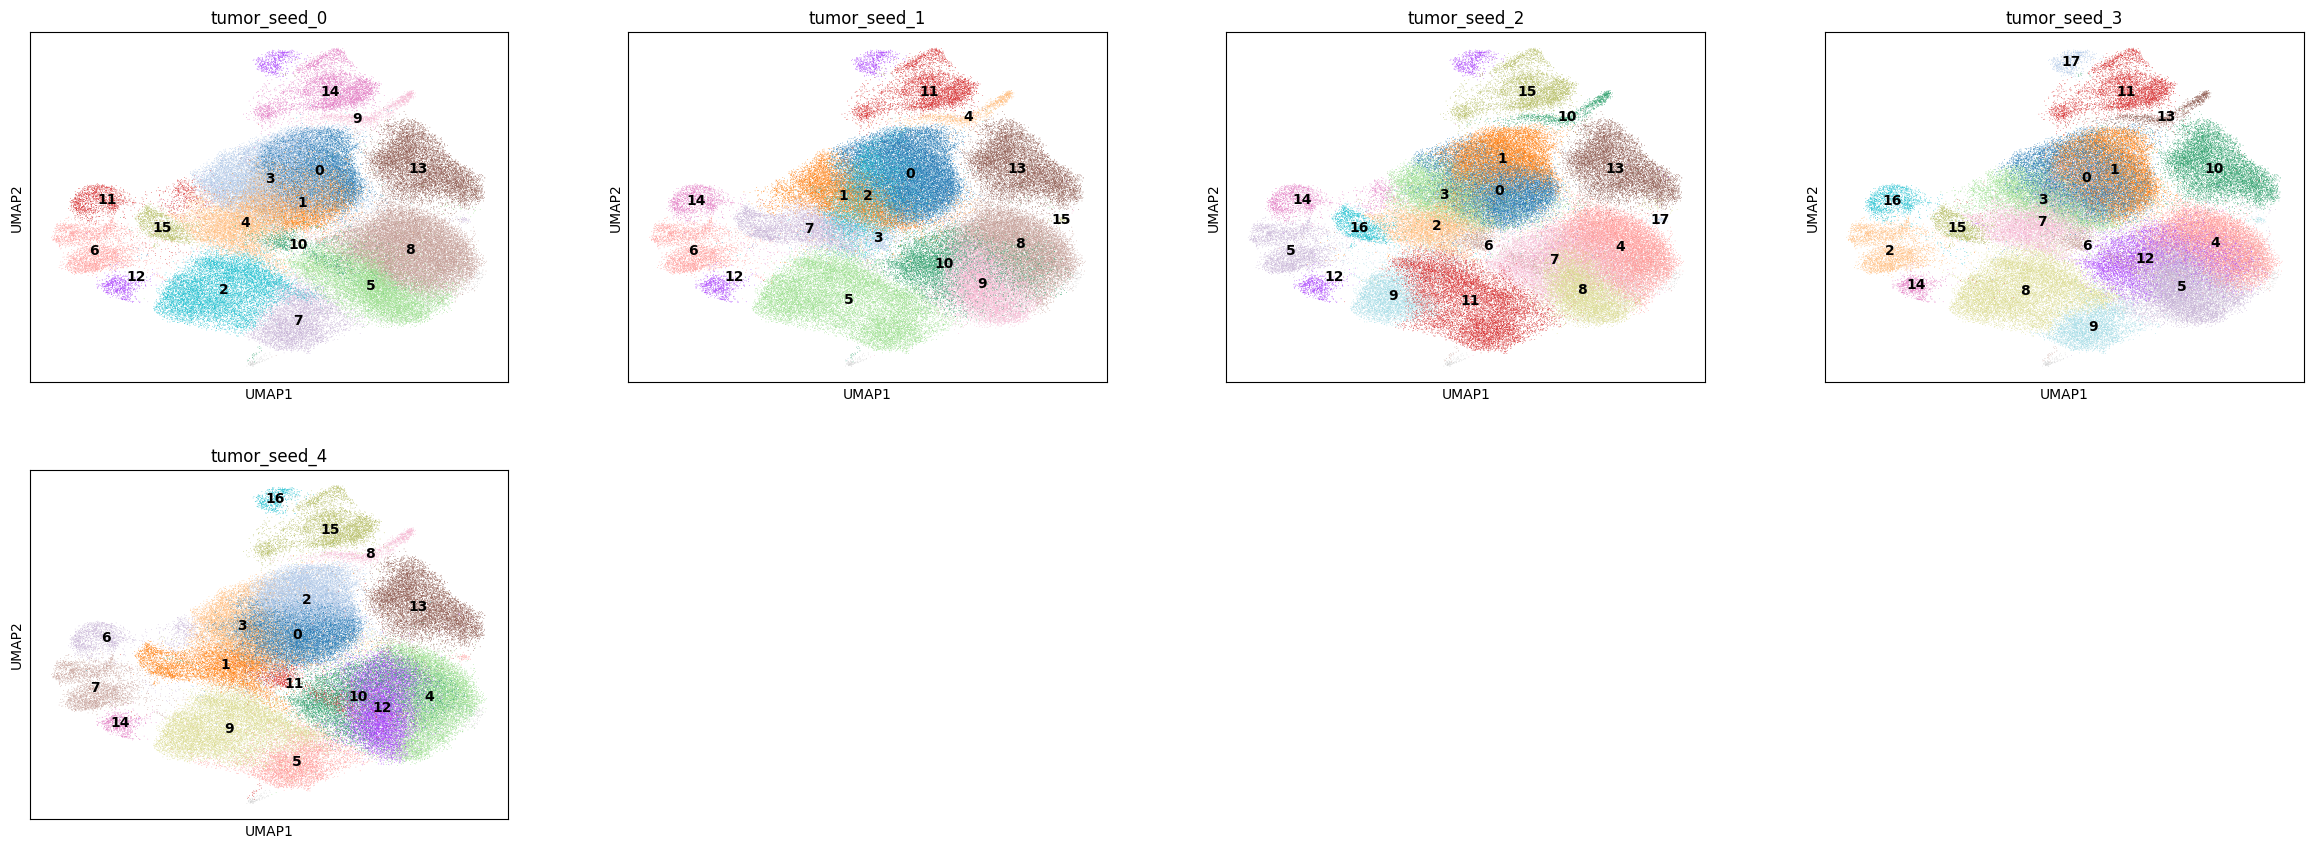

In [24]:
seed_plot_keys = []
for seed, labels in tumor_partitions.items():
    key = f"tumor_seed_{seed}"
    combined_full.obs[key] = pd.Categorical(
        pd.Series(labels, index=tumor_adata.obs_names).reindex(combined_full.obs_names))
    seed_plot_keys.append(key)

sc.pl.umap(combined_full, color=seed_plot_keys, legend_loc="on data", na_in_legend=False)

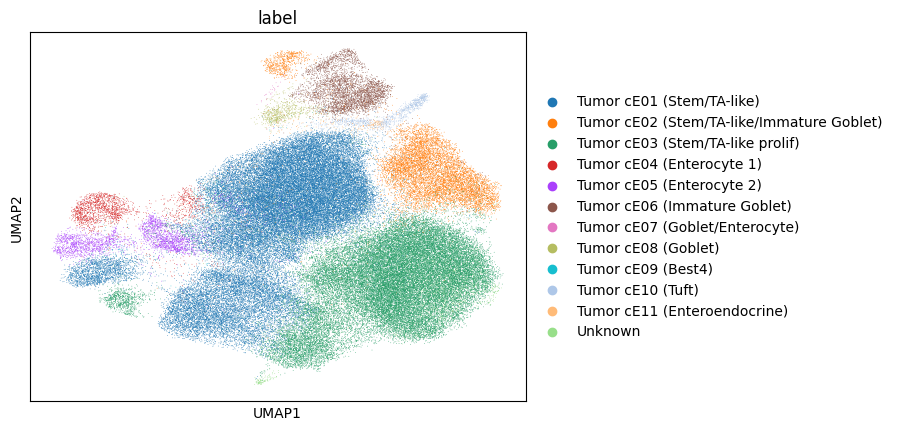

In [25]:
sc.pl.umap(combined_full, color="label")

## Save the artifact

Artifact writing is disabled for now so the existing h5ad is kept. Uncomment
the write block in the next cell when you want to regenerate it.

In [26]:
settings = {
    "approach": APPROACH,
    "config_id": CONFIG_ID,
    "num_hvg": NUM_HVG,
    "graph_seed": GRAPH_SEED,
    "sweep_seed": SWEEP_SEED,
    "leiden_seed": int(LEIDEN_SEED),
    "tumor_res": float(TUMOR_RES),
    "full_res": float(FULL_RES),
}
combined_full = clustering.freeze_and_save_artifact(
    combined_full,
    tumor_adata,
    tumor_partitions,
    full_partitions,
    settings,
)

print(f"obs columns: {list(combined_full.obs.columns)}")
print(f"uns keys: {list(combined_full.uns)}")

obs columns: ['cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'biosample_id', 'mlh1_status', 'sex', 'tissue_site', 'pathological_stage', 'tumor_grade', 'TissueSource', 'ProcessingMethod', 'TumorStage', 'LymphNodeStatus', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'tumor_leiden_res0.9', 'full_leiden_res1.0']
uns keys: ['log1p', 'neighbors', 'umap', 'bio_leiden_settings']


In [ ]:
out_path = ROOT / paths["bio"]["joint_artifact"]

# uncomment to rewrite it.
# out_path.parent.mkdir(parents=True, exist_ok=True)
# tmp_path = out_path.with_suffix(".tmp.h5ad")
#
# combined_full.write_h5ad(tmp_path)
# tmp_path.replace(out_path)

print(f"Skipping artifact write; keeping existing {out_path.relative_to(ROOT)}")
print(f"  shape={combined_full.shape}")
print(f"  graph_seed={GRAPH_SEED}, leiden_seed={LEIDEN_SEED}, tumor_res={TUMOR_RES}, full_res={FULL_RES}")
print(f"  layers={list(combined_full.layers)}, obsm={list(combined_full.obsm)}, obsp={list(combined_full.obsp)}")

In [28]:
combined_full

AnnData object with n_obs × n_vars = 110293 × 28617
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'biosample_id', 'mlh1_status', 'sex', 'tissue_site', 'pathological_stage', 'tumor_grade', 'TissueSource', 'ProcessingMethod', 'TumorStage', 'LymphNodeStatus', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'tumor_leiden_res0.9', 'full_leiden_res1.0'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'hvg'
    uns: 'log1p', 'neighbors', 'umap', 'bio_leiden_settings'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'